In [2]:
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from Bio.PDB import PDBParser
from Bio.PDB.Polypeptide import is_aa
from Bio.Data.IUPACData import protein_letters_3to1
from Bio.Align import PairwiseAligner, substitution_matrices

DATA_PATH   = "by_wild_type.csv.gz"
PDB_ID      = "1C3W"        # bacteriorhodopsin, retinal bound
PDB_CHAIN   = "A"
LIGAND      = "RET"         # retinal
POCKET_CUTOFF_A = 5.0       # angstroms from any retinal atom
SEED = 0
rng = np.random.default_rng(SEED)

In [3]:
#Data Split, same for all models
df = pd.read_csv(DATA_PATH, compression="gzip")
df["validation"] = df["validation"].astype(str).str.lower().eq("true")
df["split"] = np.where(df["validation"], "val", df["set"])
df = df.groupby(["split", "sequence"], as_index=False)["target"].mean()

train = df[df.split == "train"].reset_index(drop=True)
val   = df[df.split == "val"].reset_index(drop=True)
test  = df[df.split == "test"].reset_index(drop=True)
y_tr, y_va, y_te = train.target.values, val.target.values, test.target.values
print(df.split.value_counts().to_dict())

{'train': 578, 'test': 184, 'val': 116}


In [4]:
#Get the reference structure for pocket positions from a pdf bile
#we find the retinal lagand, keep every residue with an atom within 5A of the ligand, and return the residue numbers of those residues
#sci-py styled distance threshold on coordinate table, 0 biology beyond that

pdb_file = Path(f"{PDB_ID}.pdb")
if not pdb_file.exists():
    urllib.request.urlretrieve(f"https://files.rcsb.org/download/{PDB_ID}.pdb", pdb_file)
    
chain = PDBParser(QUIET=True).get_structure(PDB_ID, pdb_file)[0][PDB_CHAIN]

three2one = {k.upper(): v for k, v in protein_letters_3to1.items()}
res_list, ref_seq, ref_pdb_ids = [], [], []
for res in chain:
    if is_aa(res, standard=True):
        res_list.append(res)
        ref_seq.append(three2one[res.get_resname()])
        ref_pdb_ids.append(res.id[1])
ref_seq = "".join(ref_seq)
print(f"Reference chain {PDB_CHAIN}: {len(ref_seq)} residues")

ret_atoms = np.array([a.coord for r in chain if r.get_resname() == LIGAND for a in r])
assert len(ret_atoms), f"ligand {LIGAND} not found in chain {PDB_CHAIN}"

min_dist = np.array([
    np.min(np.linalg.norm(np.array([a.coord for a in res])[:, None, :] - ret_atoms[None, :, :], axis=-1))
    for res in res_list
])
pocket_idx = np.where(min_dist <= POCKET_CUTOFF_A)[0]      # 0-based index into ref_seq
pocket_pdb = [ref_pdb_ids[i] for i in pocket_idx]

print(f"Pocket residues within {POCKET_CUTOFF_A} A: {len(pocket_idx)}")
print("PDB numbering:", pocket_pdb)
for key in (85, 212, 216):
    print(f"  Lys/Asp{key} in pocket: {key in pocket_pdb}")

Reference chain A: 222 residues
Pocket residues within 5.0 A: 21
PDB numbering: [83, 85, 86, 89, 90, 93, 118, 119, 122, 138, 141, 142, 145, 182, 185, 186, 189, 208, 212, 215, 216]
  Lys/Asp85 in pocket: True
  Lys/Asp212 in pocket: True
  Lys/Asp216 in pocket: True


In [5]:
#Pairwise align every sequence to the reference sequence, and store the aligned sequences in a new column

aligner = PairwiseAligner(
    substitution_matrix=substitution_matrices.load("BLOSUM62"),
    open_gap_score=-11, extend_gap_score=-1, mode="global",
)

def project_to_reference(seq, ref=ref_seq):
    """Return a string of len(ref): residue aligned to each reference position, '-' if none."""
    aln = aligner.align(ref, seq)[0]
    out = np.full(len(ref), "-", dtype="<U1")
    ref_blocks, seq_blocks = aln.aligned
    for (r0, r1), (s0, s1) in zip(ref_blocks, seq_blocks):
        out[r0:r1] = list(seq[s0:s1])
    return "".join(out)

for frame in (train, val, test):
    frame["projected"] = [project_to_reference(s) for s in frame.sequence]
    # identity to the reference, over non-gap reference positions
    frame["pct_id"] = [
        np.mean([p == r for p, r in zip(proj, ref_seq) if p != "-"]) * 100
        for proj in frame.projected
    ]
print(pd.concat([f.assign(split=n) for n, f in
                 [("train", train), ("val", val), ("test", test)]]
               ).groupby("split").pct_id.describe()[["mean", "min", "max"]].round(1))

       mean   min    max
split                   
test   35.2  23.0  100.0
train  43.4  27.1  100.0
val    38.1  23.2   63.2


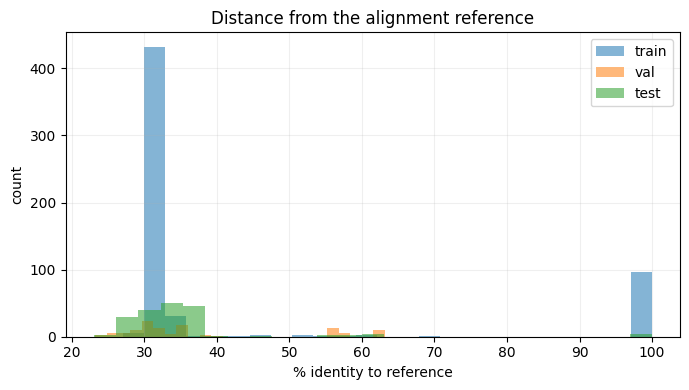

In [6]:
#Quality diagnostic, alignment is an algorithm's best guess
#guesses are not all too correct, does worst on sequences distant from referece
#concentarted in tests, error will predictably rise

fig, ax = plt.subplots(figsize=(7, 4))
for name, frame in [("train", train), ("val", val), ("test", test)]:
    ax.hist(frame.pct_id, bins=25, alpha=0.55, label=name)
ax.set(xlabel="% identity to reference", ylabel="count", title="Distance from the alignment reference")
ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

In [7]:
#Featurization, 21 token vocabulary: 20 amino acids + gap, it encodes 
#his family has no residue at this pos, which is informative

VOCAB = "ACDEFGHIKLMNPQRSTVWY-"
V_IDX = {c: i for i, c in enumerate(VOCAB)}

def onehot(projected_series, positions):
    X = np.zeros((len(projected_series), len(positions), len(VOCAB)), dtype=np.float32)
    for r, proj in enumerate(projected_series):
        for c, p in enumerate(positions):
            X[r, c, V_IDX.get(proj[p], V_IDX["-"])] = 1.0
    return X.reshape(len(projected_series), -1)

all_idx = np.arange(len(ref_seq))
FEATS = {
    "F1 full aligned": {n: onehot(f.projected, all_idx)    for n, f in [("tr", train), ("va", val), ("te", test)]},
    "F2 pocket mask":  {n: onehot(f.projected, pocket_idx) for n, f in [("tr", train), ("va", val), ("te", test)]},
}
print({k: v["tr"].shape for k, v in FEATS.items()})

{'F1 full aligned': (578, 4662), 'F2 pocket mask': (578, 441)}


In [8]:
#Group by family for an honest error bar, dataset has no column for this so we greedy cluster the test seq
#by 3-mer cosine similarity

def pseudo_families(seqs, thresh=0.90):
    S = cosine_similarity(CountVectorizer(analyzer="char", ngram_range=(3, 3),
                                          lowercase=False).fit_transform(seqs))
    labels = np.full(len(seqs), -1)
    nxt = 0
    for i in range(len(seqs)):
        if labels[i] == -1:
            labels[(S[i] >= thresh) & (labels == -1)] = nxt
            nxt += 1
    return labels

test_fam = pseudo_families(test.sequence.tolist())
print(f"{test_fam.max() + 1} pseudo-families across {len(test)} test rows "
      f"(paper: 36 wild types)")

36 pseudo-families across 184 test rows (paper: 36 wild types)


In [9]:
#Fit and Eval
ALPHAS = np.logspace(-2, 6, 17)   # widened: baselines pinned at the old 1e4 edge
results = {}

def bootstrap_ci(y_true, y_pred, groups, fn, n=2000):
    uniq = np.unique(groups)
    stats = []
    for _ in range(n):
        pick = rng.choice(uniq, size=len(uniq), replace=True)
        rows = np.concatenate([np.where(groups == g)[0] for g in pick])
        if len(np.unique(y_pred[rows])) < 2:
            continue
        stats.append(fn(y_true[rows], y_pred[rows]))
    return (np.nan, np.nan) if not stats else tuple(np.percentile(stats, [2.5, 97.5]))

def run(name, Xtr, Xva, Xte):
    scores = {}
    for a in ALPHAS:
        m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xtr, y_tr)
        scores[a] = spearmanr(y_va, m.predict(Xva)).statistic      # select on val Spearman
    best = max(scores, key=lambda k: (scores[k] if np.isfinite(scores[k]) else -np.inf))
    m = make_pipeline(StandardScaler(), Ridge(alpha=best)).fit(Xtr, y_tr)
    p_va, p_te = m.predict(Xva), m.predict(Xte)
    lo, hi = bootstrap_ci(y_te, p_te, test_fam, lambda a_, b_: spearmanr(a_, b_).statistic)
    results[name] = dict(
        alpha=best, at_edge=best in (ALPHAS[0], ALPHAS[-1]),
        val_rho=scores[best], test_rho=spearmanr(y_te, p_te).statistic,
        test_rho_lo=lo, test_rho_hi=hi,
        val_MAE=mean_absolute_error(y_va, p_va), test_MAE=mean_absolute_error(y_te, p_te),
        pred_te=p_te,
    )

mu = y_tr.mean()
results["B0 train mean"] = dict(
    alpha=np.nan, at_edge=False, val_rho=np.nan, test_rho=np.nan,
    test_rho_lo=np.nan, test_rho_hi=np.nan,
    val_MAE=mean_absolute_error(y_va, np.full(len(val), mu)),
    test_MAE=mean_absolute_error(y_te, np.full(len(test), mu)),
    pred_te=np.full(len(test), mu),
)
for name, F in FEATS.items():
    run(name, F["tr"], F["va"], F["te"])

summary = (pd.DataFrame(results).T.drop(columns="pred_te")
             .astype({c: float for c in ["alpha", "val_rho", "test_rho", "test_rho_lo",
                                         "test_rho_hi", "val_MAE", "test_MAE"]})
             .round(3))
summary

c:\Users\Jomar\VSCode\ML\Work\work\Lib\site-packages\sklearn\linear_model\_ridge.py:265: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 8.872232726275797e-09.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)
c:\Users\Jomar\VSCode\ML\Work\work\Lib\site-packages\sklearn\linear_model\_ridge.py:265: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 4.649162121950212e-08.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)
c:\Users\Jomar\VSCode\ML\Work\work\Lib\site-packages\sklearn\linear_model\_ridge.py:265: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 8.872232726275797e-09.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)


,alpha,at_edge,val_rho,test_rho,test_rho_lo,test_rho_hi,val_MAE,test_MAE
B0 train mean,NaN,False,NaN,NaN,NaN,NaN,21.361,24.603
F1 full aligned,0.010,True,0.296,0.409,0.060,0.651,21.312,22.218
F2 pocket mask,3162.278,False,0.185,0.611,0.329,0.777,23.596,21.787


## Interpretation

- test_rho_lo > 0 is the bar, anything below this and it shows model cannot have ranking ability. The only one significantly above this is F2 pocket mask

- val_rho and test_rho should agree on the signs, which is true

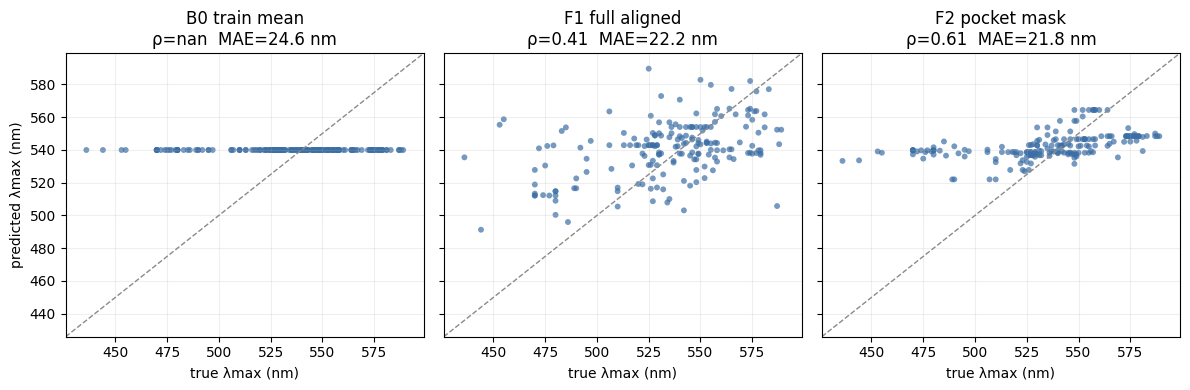

In [10]:
names = list(results)
fig, axes = plt.subplots(1, len(names), figsize=(4 * len(names), 4), sharex=True, sharey=True)
lo_, hi_ = y_te.min() - 10, y_te.max() + 10
for ax, n in zip(np.atleast_1d(axes), names):
    p = results[n]["pred_te"]
    ax.plot([lo_, hi_], [lo_, hi_], ls="--", lw=1, color="#8a8a8a")
    ax.scatter(y_te, p, s=18, alpha=0.7, color="#3b6ea5", edgecolors="none")
    ax.set(title=f"{n}\nρ={results[n]['test_rho']:.2f}  MAE={results[n]['test_MAE']:.1f} nm",
           xlabel="true λmax (nm)", xlim=(lo_, hi_), ylim=(lo_, hi_))
    ax.grid(alpha=0.2)
np.atleast_1d(axes)[0].set_ylabel("predicted λmax (nm)")
plt.tight_layout(); plt.show()

Spearman(identity, error) = -0.367  p = 3.09e-07
Strong negative => low-identity sequences dominate the error => preprocessing, not just the model.


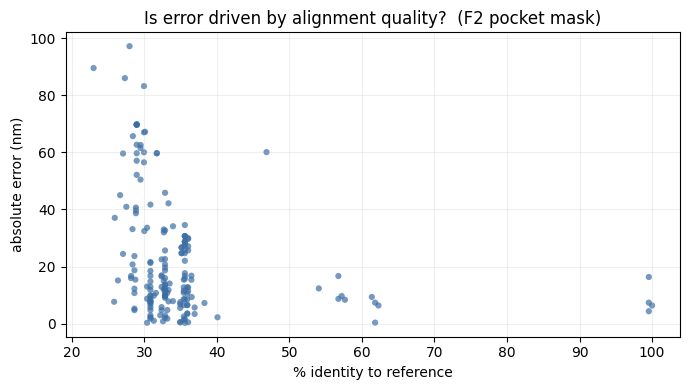

In [11]:
best_feat = max(FEATS, key=lambda k: results[k]["test_rho"])
err = np.abs(y_te - results[best_feat]["pred_te"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(test.pct_id, err, s=20, alpha=0.7, color="#3b6ea5", edgecolors="none")
ax.set(xlabel="% identity to reference", ylabel="absolute error (nm)",
       title=f"Is error driven by alignment quality?  ({best_feat})")
ax.grid(alpha=0.2)
r = spearmanr(test.pct_id, err)
print(f"Spearman(identity, error) = {r.statistic:.3f}  p = {r.pvalue:.3g}")
print("Strong negative => low-identity sequences dominate the error => preprocessing, not just the model.")
plt.tight_layout(); plt.show()